# Climate and Moisture Feature Pipeline

This loads ERA5 climate data and soil-moisture sensor data, prepares both datasets, joins them on `valid_time`, validates the combined data, analyzes relationships, and creates model-ready features using reusable classes from local Python modules.

## 1. Configure the notebook and import local modules

In [2]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

PROJECT_ROOT = Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.append(str(PROJECT_ROOT))

from dataset_processor import (
    Cleaner,
    FeatureAnalysis,
    FeatureEngineering,
    Info,
    LoadData,
    Processor,
)
from moisture_data import SoilMoistureData

pd.set_option("display.max_columns", 100)
sns.set_theme(style="whitegrid")

## 2. Smoke-test the reusable classes

In [3]:
class_names = [
    LoadData.__name__, Info.__name__, Processor.__name__,
    Cleaner.__name__, FeatureAnalysis.__name__,
    FeatureEngineering.__name__, SoilMoistureData.__name__,
]
print("Imported classes:", class_names)

# These objects confirm that the classes can be constructed in this notebook.
smoke_dataframe = pd.DataFrame({"value": [1.0, 2.0]})
smoke_cleaner = Cleaner(smoke_dataframe)
smoke_analysis = FeatureAnalysis(smoke_dataframe)
smoke_engineering = FeatureEngineering(smoke_dataframe)
print("Notebook import smoke test passed.")

Imported classes: ['LoadData', 'Info', 'Processor', 'Cleaner', 'FeatureAnalysis', 'FeatureEngineering', 'SoilMoistureData']
Notebook import smoke test passed.


## 3. Load and inspect ERA5 climate data

In [5]:
CLIMATE_DIR = PROJECT_ROOT / "data" / "climate"
climate_data = LoadData(CLIMATE_DIR)

print("Loaded climate files was successfull")

Loaded climate files was successfull


## 4. Validate source schemas with `Info`

In [6]:
climate_info = Info(climate_data)
climate_info.get_info()

Temperature and Dewpoint above the Surface
------------------------------------------------------------
Shape: (32424, 5)
Columns: ['valid_time', 'd2m', 't2m', 'latitude', 'longitude']

Head
------------------------------------------------------------
      valid_time        d2m        t2m  latitude  longitude
0  1/2/2023 0:00  283.12537  289.31265       0.1       37.8
1  1/2/2023 1:00  283.09454  289.44470       0.1       37.8
2  1/2/2023 2:00  283.20105  289.52704       0.1       37.8

Info
------------------------------------------------------------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32424 entries, 0 to 32423
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   valid_time  32424 non-null  object 
 1   d2m         32424 non-null  float64
 2   t2m         32424 non-null  float64
 3   latitude    32424 non-null  float64
 4   longitude   32424 non-null  float64
dtypes: float64(4), object(1)
memory usage: 1.

## 5. Merge climate datasets and rename ERA5 variables

In [7]:
ERA5_DICTIONARY = {
    "valid_time": {"full_name": "valid_time"},
    "d2m": {"full_name": "2m_dewpoint_temperature"},
    "t2m": {"full_name": "2_m_air_temperature"},
    "sp": {"full_name": "surface_pressure"},
    "tp": {"full_name": "total_precipitation"},
    "ssrd": {"full_name": "surface_solar_radiation_downward"},
    "strd": {"full_name": "surface_thermal_radiation_downward"},
    "skt": {"full_name": "surface_temperature"},
    "stl1": {"full_name": "soil_temperature_level_1"},
    "stl2": {"full_name": "soil_temperature_level_2"},
    "stl3": {"full_name": "soil_temperature_level_3"},
    "stl4": {"full_name": "soil_temperature_level_4"},
    "swvl1": {"full_name": "volumetric_soil_water_level_1"},
    "swvl2": {"full_name": "volumetric_soil_water_level_2"},
    "swvl3": {"full_name": "volumetric_soil_water_level_3"},
    "swvl4": {"full_name": "volumetric_soil_water_level_4"},
    "u10": {"full_name": "10m_u_component_of_wind"},
    "v10": {"full_name": "10m_v_component_of_wind"},
    "latitude": {"full_name": "latitude"},
    "longitude": {"full_name": "longitude"},
}

processor = Processor(climate_data, ERA5_DICTIONARY)
climate_merged = processor.merge()
climate_prepared = processor.process_columns(climate_merged)
climate_prepared["valid_time"] = pd.to_datetime(climate_prepared["valid_time"], errors="coerce")
climate_prepared = climate_prepared.dropna(subset=["valid_time"])

print("Climate shape:", climate_prepared.shape)
climate_prepared.head()

Climate shape: (32424, 22)


,valid_time,2m_dewpoint_temperature,2_m_air_temperature,latitude,longitude,surface_pressure,total_precipitation,surface_solar_radiation_downward,surface_thermal_radiation_downward,surface_temperature,snowc,sde,soil_temperature_level_1,soil_temperature_level_2,soil_temperature_level_3,soil_temperature_level_4,10m_u_component_of_wind,10m_v_component_of_wind,volumetric_soil_water_level_1,volumetric_soil_water_level_2,volumetric_soil_water_level_3,volumetric_soil_water_level_4
0,2023-01-02 00:00:00+00:00,283.12537,289.31265,0.1,37.8,87224.22,0.0,0.0,1226392.0,288.10630,0.0,-7.345365e-24,291.16650,295.06113,295.40176,295.72595,1.451477,0.781448,0.153107,0.168671,0.164963,0.174759
1,2023-01-02 01:00:00+00:00,283.09454,289.44470,0.1,37.8,87238.50,0.0,0.0,1265179.8,288.22073,0.0,-7.345365e-24,291.05720,294.88205,295.39902,295.72668,1.127609,0.990860,0.153046,0.168671,0.164963,0.174759
2,2023-01-02 02:00:00+00:00,283.20105,289.52704,0.1,37.8,87295.71,0.0,0.0,1267433.0,288.14673,0.0,-7.345365e-24,290.90130,294.70862,295.39820,295.72552,0.396576,1.221909,0.153000,0.168671,0.164963,0.174759
3,2023-01-02 03:00:00+00:00,283.64075,289.36370,0.1,37.8,87381.07,0.0,0.0,1252700.5,287.81530,0.0,-7.345365e-24,290.64246,294.53314,295.39536,295.72626,-0.330124,1.168304,0.152969,0.168671,0.164963,0.174759
4,2023-01-02 04:00:00+00:00,284.29858,289.33290,0.1,37.8,87458.18,0.0,46331.0,1252880.2,287.96810,0.0,-7.345365e-24,290.60890,294.36550,295.39053,295.72510,-0.510330,0.994019,0.152954,0.168671,0.164963,0.174759


## 6. Load and prepare soil-moisture sensor data

In [8]:
MOISTURE_DIR = PROJECT_ROOT / "data" / "moisture"
RAW_MOISTURE_PATH = MOISTURE_DIR / "raw.xlsx"
CLEAN_MOISTURE_PATH = MOISTURE_DIR / "clean.csv"

if RAW_MOISTURE_PATH.exists():
    moisture_loader = SoilMoistureData(RAW_MOISTURE_PATH)
    moisture = moisture_loader.get_data().copy()
else:
    # The current workspace contains clean.csv but not raw.xlsx.
    # Use the reusable Excel class automatically when the workbook is available.
    moisture_loader = None
    moisture = pd.read_csv(CLEAN_MOISTURE_PATH)

moisture["valid_time"] = pd.to_datetime(moisture["valid_time"], errors="coerce")
moisture = moisture.dropna(subset=["valid_time"])
moisture.head()

,valid_time,Port 1,Port 2,Port 3,Port 4,Port 5
0,2023-02-28 20:00:00,2533,2799,2764,2771,2765
1,2023-02-28 22:00:00,2533,2799,2764,2771,2764
2,2023-03-01 00:00:00,2533,2798,2764,2771,2763
3,2023-03-01 02:00:00,2533,2798,2764,2771,2763
4,2023-03-01 04:00:00,2533,2798,2764,2771,2763


In [9]:
# Normalize both datasets to the same timestamp precision and remove duplicate sensor times.
climate_prepared["valid_time"] = pd.to_datetime(climate_prepared["valid_time"], utc=True).dt.floor("h")
moisture["valid_time"] = pd.to_datetime(moisture["valid_time"], utc=True).dt.floor("h")

sensor_columns = [column for column in moisture.columns if column.startswith("Port ")]
moisture[sensor_columns] = moisture[sensor_columns].apply(pd.to_numeric, errors="coerce")
moisture["soil_moisture_mean"] = moisture[sensor_columns].mean(axis=1)
moisture_prepared = moisture.groupby("valid_time", as_index=False)[sensor_columns + ["soil_moisture_mean"]].mean()

print("Moisture shape:", moisture_prepared.shape)
moisture_prepared.head()

Moisture shape: (8817, 7)


,valid_time,Port 1,Port 2,Port 3,Port 4,Port 5,soil_moisture_mean
0,2023-02-28 20:00:00+00:00,2533.0,2799.0,2764.0,2771.0,2765.0,2726.4
1,2023-02-28 22:00:00+00:00,2533.0,2799.0,2764.0,2771.0,2764.0,2726.2
2,2023-03-01 00:00:00+00:00,2533.0,2798.0,2764.0,2771.0,2763.0,2725.8
3,2023-03-01 02:00:00+00:00,2533.0,2798.0,2764.0,2771.0,2763.0,2725.8
4,2023-03-01 04:00:00+00:00,2533.0,2798.0,2764.0,2771.0,2763.0,2725.8


## 7. Merge, clean, and validate the combined dataset

In [13]:
merged_data = pd.merge(
    climate_prepared,
    moisture_prepared,
    on="valid_time",
    how="inner",
    validate="one_to_one",
)

# Save the cleaned, timestamp-normalized moisture data before joining it to climate data.
cleaned_moisture_path = MOISTURE_DIR / "cleaned_moisture.csv"
moisture_prepared.to_csv(cleaned_moisture_path, index=False)

print("Merged shape:", merged_data.shape)
print(f"Cleaned moisture data saved to: {cleaned_moisture_path}")
merged_data.describe()

Merged shape: (8817, 28)
Cleaned moisture data saved to: C:\Users\HomePC\Desktop\moisture-sensor\data\moisture\cleaned_moisture.csv


,2m_dewpoint_temperature,2_m_air_temperature,latitude,longitude,surface_pressure,total_precipitation,surface_solar_radiation_downward,surface_thermal_radiation_downward,surface_temperature,snowc,sde,soil_temperature_level_1,soil_temperature_level_2,soil_temperature_level_3,soil_temperature_level_4,10m_u_component_of_wind,10m_v_component_of_wind,volumetric_soil_water_level_1,volumetric_soil_water_level_2,volumetric_soil_water_level_3,volumetric_soil_water_level_4,Port 1,Port 2,Port 3,Port 4,Port 5,soil_moisture_mean
count,8817.000000,8817.000000,8.817000e+03,8.817000e+03,8817.000000,8.817000e+03,8.817000e+03,8.817000e+03,8817.000000,8817.0,8.817000e+03,8817.000000,8817.000000,8817.000000,8817.000000,8817.000000,8817.000000,8817.000000,8817.000000,8817.000000,8817.000000,8817.000000,8817.000000,8817.000000,8817.000000,8817.000000,8817.000000
mean,287.004515,294.480563,1.000000e-01,3.780000e+01,87263.267343,8.003580e-05,8.848891e+05,1.315485e+06,295.469949,0.0,-7.345365e-24,296.169337,296.150604,296.109805,296.058441,-0.776544,1.367048,0.197937,0.208936,0.213353,0.184731,2600.809572,2817.373596,2801.173528,2830.552796,2860.890666,2782.160032
std,2.509324,3.630924,2.775715e-17,1.421166e-14,176.738931,4.193261e-04,1.161142e+06,7.607791e+04,5.372100,0.0,1.469451e-39,3.540241,1.295625,0.768361,0.296287,1.108520,1.236011,0.079579,0.063477,0.056150,0.012250,30.720705,17.952717,21.779314,19.552386,46.661671,21.724881
min,274.960020,286.729740,1.000000e-01,3.780000e+01,86495.890000,-3.702007e-08,-4.000000e+00,1.096840e+06,284.888600,0.0,-7.345365e-24,289.099820,292.609740,294.524630,295.439700,-3.439529,-2.943680,0.130981,0.159851,0.164673,0.170929,2533.000000,2798.000000,2763.000000,2771.000000,2739.000000,2725.600000
25%,285.193700,291.404050,1.000000e-01,3.780000e+01,87144.445000,0.000000e+00,0.000000e+00,1.258264e+06,291.004700,0.0,-7.345365e-24,293.321170,295.190060,295.520360,295.838840,-1.601273,0.530182,0.139099,0.167038,0.168045,0.172653,2578.000000,2807.000000,2784.000000,2819.000000,2826.000000,2766.200000
50%,287.092100,294.035640,1.000000e-01,3.780000e+01,87265.875000,7.003546e-07,4.426600e+04,1.317964e+06,294.200230,0.0,-7.345365e-24,295.463130,296.046970,295.972050,296.059140,-0.943497,1.327835,0.160538,0.180084,0.195419,0.180313,2598.000000,2815.000000,2806.000000,2832.000000,2872.000000,2781.800000
75%,288.933840,297.442840,1.000000e-01,3.780000e+01,87382.190000,1.976639e-05,1.667970e+06,1.373990e+06,299.938900,0.0,-7.345365e-24,298.711000,297.037750,296.694520,296.247650,-0.079376,2.235115,0.236877,0.227341,0.238693,0.197464,2619.000000,2818.000000,2814.000000,2841.000000,2896.000000,2792.600000
max,294.229370,304.440120,1.000000e-01,3.780000e+01,87958.160000,8.728556e-03,3.920512e+06,1.520490e+06,310.373300,0.0,-7.345365e-24,307.399320,300.110300,298.030120,296.662930,2.589966,5.975052,0.447708,0.447708,0.419525,0.203369,2668.000000,2872.000000,2849.000000,2885.000000,2961.000000,2843.200000


## 8. Plot the merged climate and moisture data

The plots are generated before feature analysis and feature engineering. All five sensor targets are shown together for comparison.

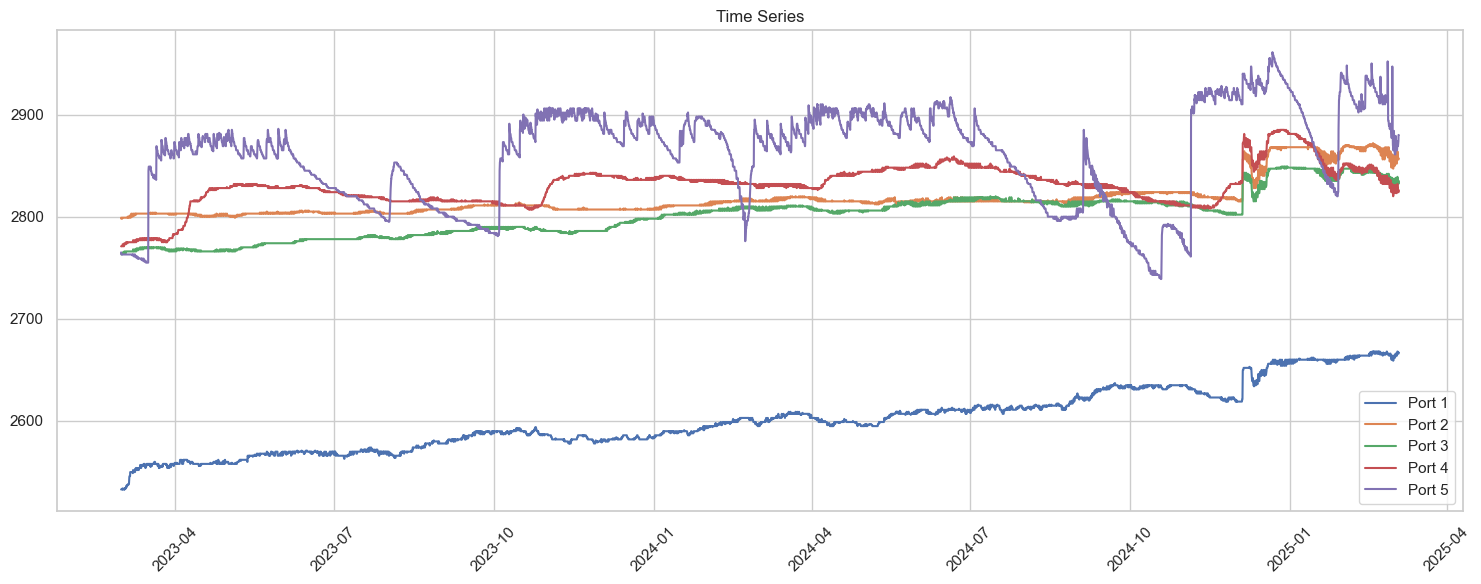

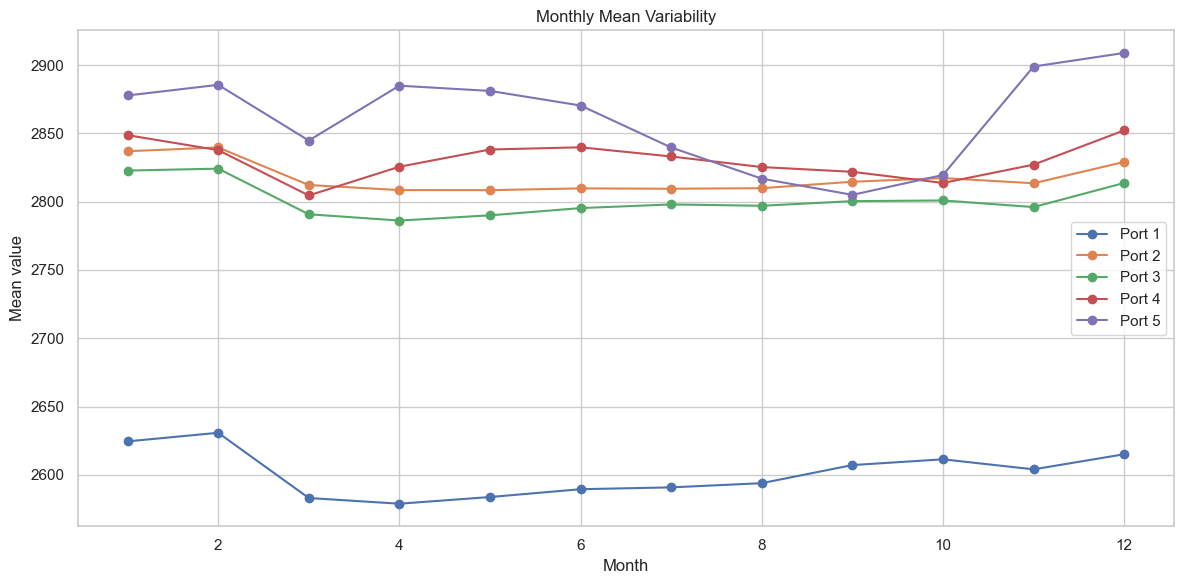

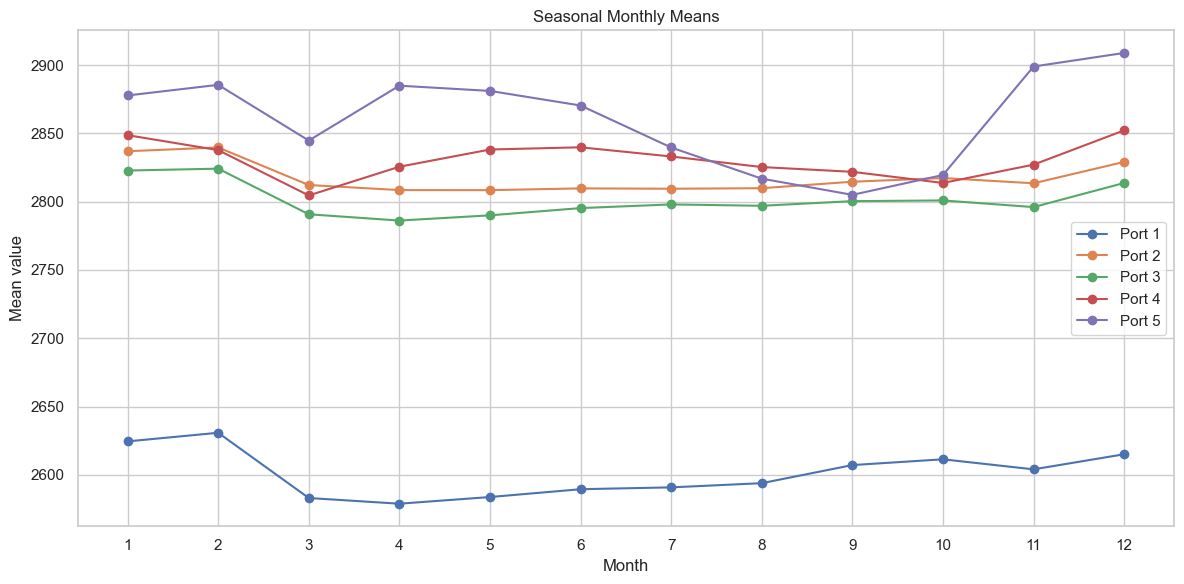

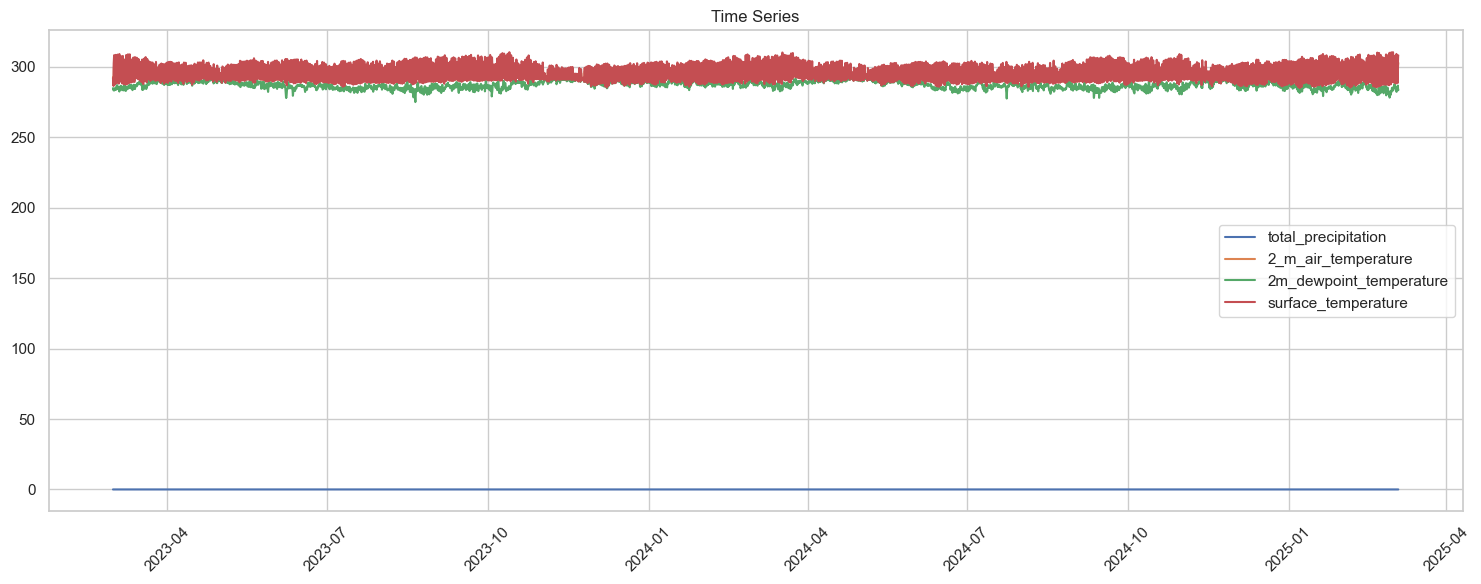

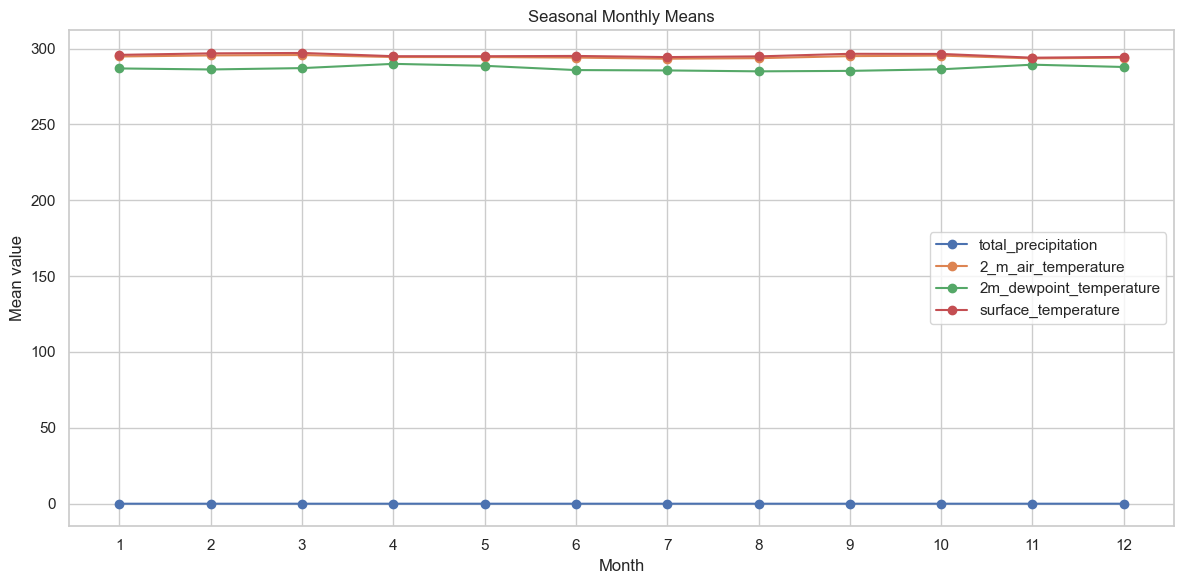

In [11]:
TARGET_COLUMNS = [f"Port {port}" for port in range(1, 6)]

# Plot all five sensor targets together after the climate-moisture merge.
plot_analysis = FeatureAnalysis(
    merged_data,
    target=TARGET_COLUMNS,
    datetime_column="valid_time",
)
plot_analysis.time_series_analysis(TARGET_COLUMNS)
plot_analysis.time_variability(TARGET_COLUMNS)
plot_analysis.seasonal_analysis(TARGET_COLUMNS)

# Plot selected climate variables together for comparison.
CLIMATE_PLOT_COLUMNS = [
    "total_precipitation",
    "2_m_air_temperature",
    "2m_dewpoint_temperature",
    "surface_temperature",
]
available_climate_plot_columns = [
    column for column in CLIMATE_PLOT_COLUMNS if column in merged_data.columns
]
if available_climate_plot_columns:
    plot_analysis.time_series_analysis(available_climate_plot_columns)
    plot_analysis.seasonal_analysis(available_climate_plot_columns)
else:
    print("No selected climate plotting columns are available.")

## 9. Analyze the merged climate-moisture data

Run descriptive statistics, missing-value checks, variance analysis, correlations, target relationships, mutual information, and VIF before selecting columns to remove.

Rows: 8,817
Columns: 28
valid_time                            datetime64[ns, UTC]
2m_dewpoint_temperature                           float64
2_m_air_temperature                               float64
latitude                                          float64
longitude                                         float64
surface_pressure                                  float64
total_precipitation                               float64
surface_solar_radiation_downward                  float64
surface_thermal_radiation_downward                float64
surface_temperature                               float64
snowc                                             float64
sde                                               float64
soil_temperature_level_1                          float64
soil_temperature_level_2                          float64
soil_temperature_level_3                          float64
soil_temperature_level_4                          float64
10m_u_component_of_wind                         

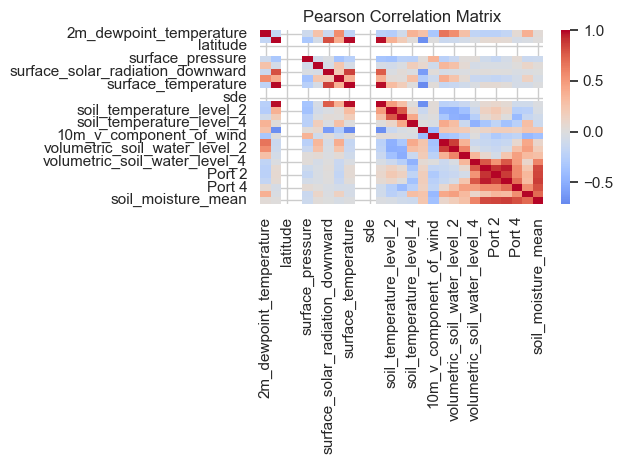

             feature_1                 feature_2  correlation
0  2_m_air_temperature       surface_temperature     0.981726
1  2_m_air_temperature  soil_temperature_level_1     0.979004
2  surface_temperature  soil_temperature_level_1     0.973932
3               Port 1                    Port 3     0.957312
                                      Port 1    Port 2    Port 3    Port 4  \
2m_dewpoint_temperature            -0.223105 -0.225010 -0.181208  0.046566   
2_m_air_temperature                 0.062448  0.068598  0.045328 -0.057222   
latitude                                 NaN       NaN       NaN       NaN   
longitude                                NaN       NaN       NaN       NaN   
surface_pressure                   -0.104299 -0.166303 -0.075583  0.056662   
total_precipitation                -0.037280 -0.044370 -0.036780  0.011918   
surface_solar_radiation_downward    0.020694  0.012571  0.000520 -0.030510   
surface_thermal_radiation_downward -0.153410 -0.178169 -0.147504 -

In [14]:
TARGET_COLUMNS = [f"Port {port}" for port in range(1, 6)]
SCALE_COLUMNS = [
    "total_precipitation",
    "surface_solar_radiation_downward",
    "surface_thermal_radiation_downward",
    "surface_temperature",
    "soil_temperature_level_1",
    "soil_temperature_level_2",
    "soil_temperature_level_3",
    "soil_temperature_level_4",
]

analysis = FeatureAnalysis(
    merged_data,
    target=TARGET_COLUMNS,
    datetime_column="valid_time",
)

analysis.basic_info()
descriptive_stats = analysis.descriptive_statistics()
missing_stats = analysis.missing_values()
variance_stats = analysis.variance_analysis()
correlation_stats = analysis.correlation_matrix()
high_correlation_stats = analysis.highly_correlated_features(threshold=0.90)
target_correlation_stats = analysis.target_correlation()
mutual_information_stats = analysis.mutual_information()
vif_stats = analysis.vif_analysis() if len(merged_data.select_dtypes(include=np.number).columns) > 1 else pd.DataFrame()

print("Feature analysis complete. Review correlation results before dropping columns.")

## 10. Clean the merged data and review columns to drop

In [15]:
OUTPUT_DIR = PROJECT_ROOT / "data" / "processed"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

cleaner = Cleaner(merged_data)
cleaner.process_datetime()
cleaner.check_duplicates()
cleaner.check_missing()
cleaner.check_infinite()
cleaner.check_physical_ranges()
cleaner.clean_surface_pressure()
cleaner.remove_duplicates()
cleaner.sort_data()

cleaned_data = cleaner.get_data()

# Drop redundant columns from the correlation results while protecting all targets
# and the climate features required for scaling.
protected_columns = set(TARGET_COLUMNS + SCALE_COLUMNS)
UNNECESSARY_COLUMNS = [
    "surface_pressure",
    "latitude",
    "longitude",
    "snowc",
    "sde",
    "snow_depth",
]
columns_to_drop = analysis.drop_unnecessary_columns(
    correlation_threshold=0.95,
    protected_columns=protected_columns,
    columns_to_drop=UNNECESSARY_COLUMNS,
)
cleaned_data = cleaned_data.drop(columns=columns_to_drop, errors="ignore")
cleaned_data.to_csv(OUTPUT_DIR / "merged_cleaned_data.csv", index=False)

print("Columns dropped from correlation results:", columns_to_drop)
print("Cleaned merged shape:", cleaned_data.shape)
print(f"Cleaned merged data saved to: {OUTPUT_DIR / 'merged_cleaned_data.csv'}")

Minimum time: 2023-02-28 20:00:00+00:00
Maximum time: 2025-03-04 12:00:00+00:00
Invalid datetime values: 0
Duplicate rows: 0
No missing values found.
No infinite values found.
latitude                         0
longitude                        0
volumetric_soil_water_level_1    0
volumetric_soil_water_level_2    0
volumetric_soil_water_level_3    0
volumetric_soil_water_level_4    0
snowc                            0
dtype: int64
0 zero values in surface_pressure converted to NaN.
Removed 0 duplicate rows.
Data sorted by ['valid_time', 'latitude', 'longitude'].
             feature_1                 feature_2  correlation
0  2_m_air_temperature       surface_temperature     0.981726
1  2_m_air_temperature  soil_temperature_level_1     0.979004
2  surface_temperature  soil_temperature_level_1     0.973932
3               Port 1                    Port 3     0.957312
Dropped 6 unnecessary columns.
Columns dropped: ['2_m_air_temperature', 'latitude', 'longitude', 'sde', 'snowc', 'surface_

## 11. Engineer features, remove outliers, and scale predictors

In [16]:
feature_engineering = FeatureEngineering(cleaned_data)

# The correlation-driven drop was already applied in the previous stage.
feature_engineering.create_time_features()
feature_engineering.create_wind_speed()
feature_engineering.create_dewpoint_depression()

outlier_columns = [
    column for column in [
        "2_m_air_temperature",
        "wind_speed",
        "dewpoint_depression",
    ]
    if column in feature_engineering.df
]
if outlier_columns:
    outlier_report = feature_engineering.detect_outliers(outlier_columns)
    feature_engineering.remove_outliers(outlier_columns)

# Apply log1p only to non-negative, positively skewed variables.
log_candidates = [
    column for column in ["total_precipitation", "wind_speed"]
    if column in feature_engineering.df
    and (feature_engineering.df[column] >= 0).all()
]
feature_engineering.log_transform(log_candidates)
skewness_stats = feature_engineering.check_skewness()

# Scale the requested climate features with one fitted StandardScaler.
scale_columns = [
    column for column in SCALE_COLUMNS
    if column in feature_engineering.df
]
feature_engineering.fit_standard_scaler(scale_columns)

engineered_data = feature_engineering.get_data()
engineered_data.head()

Temperature or dewpoint column not found.


,valid_time,2m_dewpoint_temperature,total_precipitation,surface_solar_radiation_downward,surface_thermal_radiation_downward,surface_temperature,soil_temperature_level_1,soil_temperature_level_2,soil_temperature_level_3,soil_temperature_level_4,10m_u_component_of_wind,10m_v_component_of_wind,volumetric_soil_water_level_1,volumetric_soil_water_level_2,volumetric_soil_water_level_3,volumetric_soil_water_level_4,Port 1,Port 2,Port 3,Port 4,Port 5,soil_moisture_mean,hour,day,month,day_of_week,day_of_year,wind_speed
0,2023-02-28 20:00:00+00:00,284.82748,-0.191311,-0.758090,-1.286121,-0.686960,-0.349520,1.312241,1.299983,0.020696,1.530060,0.355911,0.135178,0.161331,0.164734,0.17363,2533.0,2799.0,2764.0,2771.0,2765.0,2726.4,20,28,2,1,59,0.944260
1,2023-02-28 22:00:00+00:00,284.80720,-0.191311,-0.758090,-1.379328,-1.029301,-0.766131,1.030069,1.300204,0.030581,1.622513,0.416901,0.135147,0.161331,0.164734,0.17363,2533.0,2799.0,2764.0,2771.0,2764.0,2726.2,22,28,2,1,59,0.984031
2,2023-03-01 00:00:00+00:00,284.67810,-0.191311,-0.758090,-1.832497,-1.298509,-1.097354,0.703202,1.298293,0.033955,1.467438,0.315567,0.135132,0.161331,0.164734,0.17363,2533.0,2798.0,2764.0,2771.0,2763.0,2725.8,0,1,3,2,60,0.916685
3,2023-03-01 02:00:00+00:00,283.82343,-0.191311,-0.758090,-2.018133,-1.538168,-1.391804,0.339138,1.288866,0.037261,0.907898,0.928314,0.135117,0.161316,0.164734,0.17363,2533.0,2798.0,2764.0,2771.0,2763.0,2725.8,2,1,3,2,60,0.832247
4,2023-03-01 04:00:00+00:00,283.31420,-0.191311,-0.738739,-2.168501,-1.682650,-1.609831,-0.037571,1.276969,0.040567,0.576614,1.007843,0.135117,0.161316,0.164734,0.17363,2533.0,2798.0,2764.0,2771.0,2763.0,2725.8,4,1,3,2,60,0.770633


In [17]:
engineered_data.columns.to_list()

['valid_time',
 '2m_dewpoint_temperature',
 'total_precipitation',
 'surface_solar_radiation_downward',
 'surface_thermal_radiation_downward',
 'surface_temperature',
 'soil_temperature_level_1',
 'soil_temperature_level_2',
 'soil_temperature_level_3',
 'soil_temperature_level_4',
 '10m_u_component_of_wind',
 '10m_v_component_of_wind',
 'volumetric_soil_water_level_1',
 'volumetric_soil_water_level_2',
 'volumetric_soil_water_level_3',
 'volumetric_soil_water_level_4',
 'Port 1',
 'Port 2',
 'Port 3',
 'Port 4',
 'Port 5',
 'soil_moisture_mean',
 'hour',
 'day',
 'month',
 'day_of_week',
 'day_of_year',
 'wind_speed']

## 12. Save reproducible outputs for modeling

In [18]:
OUTPUT_DIR = PROJECT_ROOT / "data" / "processed"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

cleaned_path = OUTPUT_DIR / "merged_cleaned_data.csv"
engineered_path = OUTPUT_DIR / "engineered_features.csv"
cleaned_data.to_csv(cleaned_path, index=False)
engineered_data.to_csv(engineered_path, index=False)

descriptive_stats.to_csv(OUTPUT_DIR / "descriptive_statistics.csv")
missing_stats.to_csv(OUTPUT_DIR / "missing_values.csv")
variance_stats.to_csv(OUTPUT_DIR / "variance_statistics.csv")
correlation_stats.to_csv(OUTPUT_DIR / "correlation_matrix.csv")
if isinstance(vif_stats, pd.DataFrame) and not vif_stats.empty:
    vif_stats.to_csv(OUTPUT_DIR / "vif_statistics.csv", index=False)

# Parquet is optional because it requires a parquet engine such as pyarrow.
try:
    engineered_data.to_parquet(OUTPUT_DIR / "engineered_features.parquet", index=False)
except ImportError:
    print("Parquet export skipped; install pyarrow to enable it.")

print(f"Saved cleaned data to: {cleaned_path}")
print(f"Saved engineered data to: {engineered_path}")

Saved cleaned data to: C:\Users\HomePC\Desktop\moisture-sensor\data\processed\merged_cleaned_data.csv
Saved engineered data to: C:\Users\HomePC\Desktop\moisture-sensor\data\processed\engineered_features.csv


In [19]:
engineered_data.head()

,valid_time,2m_dewpoint_temperature,total_precipitation,surface_solar_radiation_downward,surface_thermal_radiation_downward,surface_temperature,soil_temperature_level_1,soil_temperature_level_2,soil_temperature_level_3,soil_temperature_level_4,10m_u_component_of_wind,10m_v_component_of_wind,volumetric_soil_water_level_1,volumetric_soil_water_level_2,volumetric_soil_water_level_3,volumetric_soil_water_level_4,Port 1,Port 2,Port 3,Port 4,Port 5,soil_moisture_mean,hour,day,month,day_of_week,day_of_year,wind_speed
0,2023-02-28 20:00:00+00:00,284.82748,-0.191311,-0.758090,-1.286121,-0.686960,-0.349520,1.312241,1.299983,0.020696,1.530060,0.355911,0.135178,0.161331,0.164734,0.17363,2533.0,2799.0,2764.0,2771.0,2765.0,2726.4,20,28,2,1,59,0.944260
1,2023-02-28 22:00:00+00:00,284.80720,-0.191311,-0.758090,-1.379328,-1.029301,-0.766131,1.030069,1.300204,0.030581,1.622513,0.416901,0.135147,0.161331,0.164734,0.17363,2533.0,2799.0,2764.0,2771.0,2764.0,2726.2,22,28,2,1,59,0.984031
2,2023-03-01 00:00:00+00:00,284.67810,-0.191311,-0.758090,-1.832497,-1.298509,-1.097354,0.703202,1.298293,0.033955,1.467438,0.315567,0.135132,0.161331,0.164734,0.17363,2533.0,2798.0,2764.0,2771.0,2763.0,2725.8,0,1,3,2,60,0.916685
3,2023-03-01 02:00:00+00:00,283.82343,-0.191311,-0.758090,-2.018133,-1.538168,-1.391804,0.339138,1.288866,0.037261,0.907898,0.928314,0.135117,0.161316,0.164734,0.17363,2533.0,2798.0,2764.0,2771.0,2763.0,2725.8,2,1,3,2,60,0.832247
4,2023-03-01 04:00:00+00:00,283.31420,-0.191311,-0.738739,-2.168501,-1.682650,-1.609831,-0.037571,1.276969,0.040567,0.576614,1.007843,0.135117,0.161316,0.164734,0.17363,2533.0,2798.0,2764.0,2771.0,2763.0,2725.8,4,1,3,2,60,0.770633
